# Analisis penjualan Walmart
## Keputusan yang ingin dibantu
Bagaimana manajer toko menyiapkan kapasitas menjelang periode ramai dan memilih toko yang perlu diperiksa lebih dulu?

Kita menjawab empat pertanyaan:
1. Kapan penjualan mingguan paling tinggi, setelah memperhatikan jumlah minggu tiap bulan?
2. Toko mana yang menyumbang penjualan terbesar dan toko mana yang turun pada periode sebanding?
3. Seberapa berbeda penjualan pada minggu berlabel libur?
4. Apakah hubungan faktor ekonomi dengan penjualan tetap terlihat setelah perbedaan skala toko dikurangi?

Satu baris adalah **satu toko pada satu tanggal minggu**. Anggap setiap baris sebagai satu lembar rekap kasir mingguan. Kita tidak mempunyai rincian barang, pelanggan, stok, biaya, atau laba. Weekly_Sales diperlakukan sebagai nilai penjualan USD sesuai konteks dataset. Ini analisis historis 2010–2012, bukan keadaan Walmart saat ini.

Cara membaca: baca catatan sebelum kode, jalankan dari atas, lalu cocokkan hasil dengan pertanyaan bisnis. Versi tersimpan sudah berisi keluaran analisis. Sel bertanda opsional tidak dijalankan pada pengujian lokal.

## 1 Menyiapkan alat
pandas membantu merapikan tabel. matplotlib menggambar grafik. KaggleHub mengambil dataset. Jalankan sel instalasi sekali di Colab jika paket belum tersedia. Versi paket dicatat agar hasil bisa ditelusuri.

In [ ]:
# Opsional di Colab. Hapus tanda # lalu jalankan jika paket belum tersedia.
# %pip install -q pandas numpy matplotlib kagglehub gspread google-auth

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import hashlib, json, platform
# Bekerja dari folder repository, dari notebooks/, atau dari /content di Colab.
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
for folder in ['data/raw', 'data/processed', 'outputs/reports', 'outputs/figures']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
print({'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__, 'matplotlib': matplotlib.__version__})

{'python': '3.12.14', 'pandas': '2.2.3', 'numpy': '2.3.5', 'matplotlib': '3.10.8'}


## 2 Mengambil sumber dan menyimpan jejaknya
Jika CSV sudah tersedia, kita membacanya langsung. Jika belum, KaggleHub mengambil versi terbaru seperti permintaan proyek. Nilai SHA256 adalah sidik jari berkas: kita bisa membedakan sumber yang sama dari versi yang sudah berubah. Unduhan terbaru pada masa depan dapat menghasilkan angka berbeda.

Pada eksekusi yang disertakan, berkas diambil dari endpoint unduhan resmi Kaggle karena KaggleHub belum tersedia di lingkungan lokal. Notebook tetap menyediakan jalur KaggleHub untuk Colab. CSV mentah tidak disertakan dalam paket publik. Lihat catatan sumber dan redistribusi di data/README.md.

In [2]:
source = ROOT / 'data/raw/Walmart_Sales.csv'
download_path = 'local CSV from official Kaggle download'
if not source.exists():
    import kagglehub
    import shutil
    path = kagglehub.dataset_download('mikhail1681/walmart-sales')
    print('Path to dataset files:', path)
    matches = list(Path(path).rglob('Walmart_Sales.csv'))
    if len(matches) != 1:
        raise ValueError('Periksa nama CSV pada folder unduhan sebelum melanjutkan.')
    shutil.copy2(matches[0], source)
    download_path = str(path)
raw = pd.read_csv(source)
provenance = {'dataset': 'mikhail1681/walmart-sales', 'source_url': 'https://www.kaggle.com/datasets/mikhail1681/walmart-sales',
              'download_path': download_path, 'sha256': hashlib.sha256(source.read_bytes()).hexdigest(),
              'rows': len(raw), 'analysis_date': '2026-10-28', 'kaggle_version': 'not recorded; identify snapshot by sha256'}
(ROOT / 'outputs/reports/provenance.json').write_text(json.dumps(provenance, indent=2))
print(raw.head().to_string(index=False))
print(provenance)

 Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price        CPI  Unemployment
     1 05-02-2010    1643690.90             0        42.31       2.572 211.096358         8.106
     1 12-02-2010    1641957.44             1        38.51       2.548 211.242170         8.106
     1 19-02-2010    1611968.17             0        39.93       2.514 211.289143         8.106
     1 26-02-2010    1409727.59             0        46.63       2.561 211.319643         8.106
     1 05-03-2010    1554806.68             0        46.50       2.625 211.350143         8.106
{'dataset': 'mikhail1681/walmart-sales', 'source_url': 'https://www.kaggle.com/datasets/mikhail1681/walmart-sales', 'download_path': 'local CSV from official Kaggle download', 'sha256': '0846b6941217dd938ceba6ae04650ccbbd01f4877a5f88bfa4dbecda54806c8f', 'rows': 6435, 'analysis_date': '2026-10-28', 'kaggle_version': 'not recorded; identify snapshot by sha256'}


## 3 Memeriksa dan membersihkan data
Kita cek kolom wajib, nilai kosong, duplikasi, serta apakah setiap toko punya minggu yang sama. Tanggal memakai format **hari-bulan-tahun**. Salah membaca 05-02-2010 sebagai 2 Mei akan menggeser grafik bulanan.

Duplikat yang persis sama dibuang dan jumlahnya dicatat. Dua baris dengan toko dan tanggal sama tetapi isi berbeda membuat proses berhenti: memilih salah satu tanpa alasan bisa mengubah total. Nilai tidak valid juga menghentikan proses. Penjualan tinggi tetap dipertahankan karena bisa memang berasal dari musim ramai.

In [3]:
required = ['Store','Date','Weekly_Sales','Holiday_Flag','Temperature','Fuel_Price','CPI','Unemployment']
assert set(required).issubset(raw.columns), 'Kolom wajib tidak lengkap'
exact_duplicates = int(raw.duplicated().sum())
df = raw.drop_duplicates().copy()
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='raise')
for column in [c for c in required if c != 'Date']:
    df[column] = pd.to_numeric(df[column], errors='raise')
assert df[required].notna().all().all(), 'Ada nilai kosong; periksa sumber'
assert np.isfinite(df.select_dtypes('number')).all().all(), 'Ada angka nonfinite'
assert not df.duplicated(['Store','Date']).any(), 'Kunci toko-minggu berkonflik'
assert df['Store'].gt(0).all() and df['Store'].mod(1).eq(0).all()
assert df['Weekly_Sales'].ge(0).all()
assert df['Holiday_Flag'].isin([0,1]).all()
assert df.groupby('Date')['Holiday_Flag'].nunique().max() == 1
calendar = pd.date_range(df['Date'].min(), df['Date'].max(), freq='7D')
expected = pd.MultiIndex.from_product([sorted(df.Store.unique()), calendar], names=['Store','Date'])
missing_keys = expected.difference(pd.MultiIndex.from_frame(df[['Store','Date']]))
assert len(missing_keys) == 0, 'Ada minggu toko yang hilang'
assert len(df) == len(expected), 'Ada tanggal di luar kalender mingguan'
df = df.sort_values(['Date','Store']).reset_index(drop=True)
df['Year'] = df.Date.dt.year
df['Month'] = df.Date.dt.month
df['Year_Month'] = df.Date.dt.strftime('%Y-%m')
df['Holiday_Label'] = df.Holiday_Flag.map({0:'Nonlibur',1:'Libur'})
quality = pd.DataFrame({'Pemeriksaan':['Baris sumber','Duplikat persis dibuang','Nilai kosong','Kunci ganda setelah cleaning','Minggu toko hilang','Toko','Tanggal minggu'],
 'Hasil':[len(raw),exact_duplicates,int(df[required].isna().sum().sum()),int(df.duplicated(['Store','Date']).sum()),len(missing_keys),df.Store.nunique(),df.Date.nunique()]})
quality.to_csv(ROOT/'outputs/reports/data_quality.csv', index=False)
print(quality.to_string(index=False))
print('Periode:',df.Date.min().date(),'sampai',df.Date.max().date())

                 Pemeriksaan  Hasil
                Baris sumber   6435
     Duplikat persis dibuang      0
                Nilai kosong      0
Kunci ganda setelah cleaning      0
          Minggu toko hilang      0
                        Toko     45
              Tanggal minggu    143
Periode: 2010-02-05 sampai 2012-10-26


## 4 Menetapkan ukuran yang dipakai
Total penjualan = jumlah Weekly_Sales. Rata-rata mingguan jaringan = total bulan dibagi jumlah tanggal minggu yang teramati. Rata-rata toko per minggu = total dibagi jumlah baris toko-minggu.

Bayangkan dua ember yang diisi selama empat dan lima menit. Ember kedua bisa lebih penuh karena waktu pengisiannya lebih lama. Begitu juga total bulan dengan empat dan lima minggu. Kita tampilkan total dan laju mingguannya bersama.

Tanggal mingguan ditempatkan pada bulan tanggal tersebut. Kita tidak membagi satu minggu menjadi transaksi harian karena rincian hariannya tidak tersedia. Februari 2010 dan Oktober 2012 adalah batas cakupan. Perbandingan tahun memakai minggu kalender ISO yang sama dan menampilkan juga tanggal pembanding agar selisih kalender terlihat.

In [4]:
weekly = df.groupby('Date', as_index=False).agg(Sales=('Weekly_Sales','sum'), Holiday_Flag=('Holiday_Flag','first'))
monthly = df.groupby('Year_Month', as_index=False).agg(Total_Sales=('Weekly_Sales','sum'), Weeks_Observed=('Date','nunique'), Store_Weeks=('Store','size'))
monthly['Avg_Weekly_Network'] = monthly.Total_Sales / monthly.Weeks_Observed
monthly['Avg_Store_Week'] = monthly.Total_Sales / monthly.Store_Weeks
monthly['Coverage'] = np.where(monthly.Year_Month.isin(['2010-02','2012-10']), 'Batas cakupan', 'Dalam cakupan')
monthly['MoM_Weekly_Avg_Pct'] = monthly.Avg_Weekly_Network.pct_change()*100
monthly.to_csv(ROOT/'outputs/reports/monthly_summary.csv',index=False)
kpi = {'total_sales':float(df.Weekly_Sales.sum()),'stores':int(df.Store.nunique()),'weeks':int(df.Date.nunique()),'rows':len(df),
       'avg_weekly_network':float(weekly.Sales.mean()),'start':str(df.Date.min().date()),'end':str(df.Date.max().date())}
print(json.dumps(kpi,indent=2))
print(monthly.to_string(index=False))

{
  "total_sales": 6737218987.11,
  "stores": 45,
  "weeks": 143,
  "rows": 6435,
  "avg_weekly_network": 47113419.49027973,
  "start": "2010-02-05",
  "end": "2012-10-26"
}
Year_Month  Total_Sales  Weeks_Observed  Store_Weeks  Avg_Weekly_Network  Avg_Store_Week      Coverage  MoM_Weekly_Avg_Pct
   2010-02 190332983.04               4          180        4.758325e+07    1.057405e+06 Batas cakupan                 NaN
   2010-03 181919802.50               4          180        4.547995e+07    1.010666e+06 Dalam cakupan           -4.420243
   2010-04 231412368.05               5          225        4.628247e+07    1.028499e+06 Dalam cakupan            1.764564
   2010-05 186710934.34               4          180        4.667773e+07    1.037283e+06 Dalam cakupan            0.854017
   2010-06 192246172.36               4          180        4.806154e+07    1.068034e+06 Dalam cakupan            2.964603
   2010-07 232580125.98               5          225        4.651603e+07    1.033689e+06

## 5 Menjawab kapan permintaan meningkat
Grafik pertama melihat lonjakan tiap minggu. Grafik kedua membandingkan rata-rata mingguan tiap bulan. Kita belum mengubah pola ini menjadi ramalan. Untuk menyiapkan kapasitas, mulai dari pola historis lalu periksa stok dan kapasitas aktual sebelum menentukan tambahan tenaga atau barang.

Lima minggu tertinggi:
      Date       Sales  Holiday_Flag
2010-12-24 80931415.60             0
2011-12-23 76998241.31             0
2011-11-25 66593605.26             1
2010-11-26 65821003.24             1
2010-12-17 61820799.85             0
Bulan tertinggi setelah penyesuaian jumlah minggu:
Year_Month  Total_Sales  Weeks_Observed  Store_Weeks  Avg_Weekly_Network  Avg_Store_Week      Coverage  MoM_Weekly_Avg_Pct
   2010-12 288760532.72               5          225        5.775211e+07    1.283380e+06 Dalam cakupan           13.879511
   2011-12 288078102.48               5          225        5.761562e+07    1.280347e+06 Dalam cakupan            9.659259
   2011-11 210162354.87               4          180        5.254059e+07    1.167569e+06 Dalam cakupan           14.679081


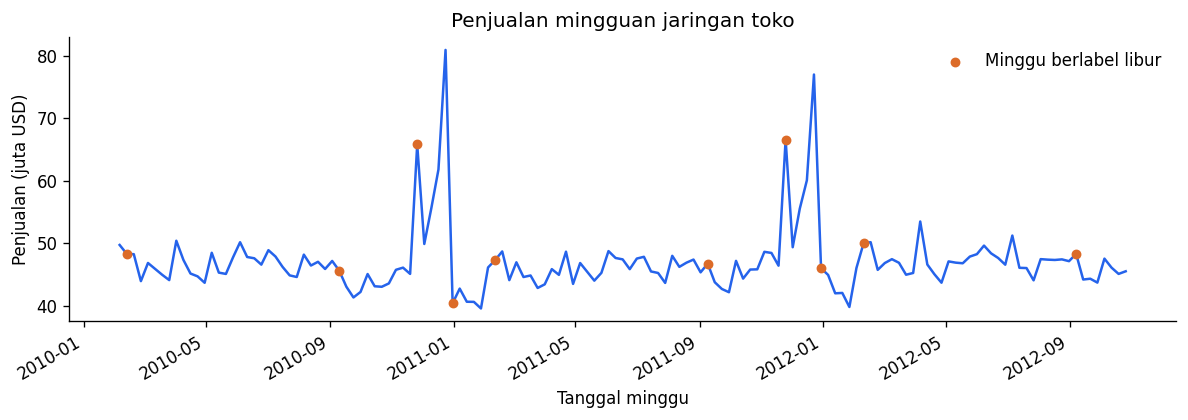

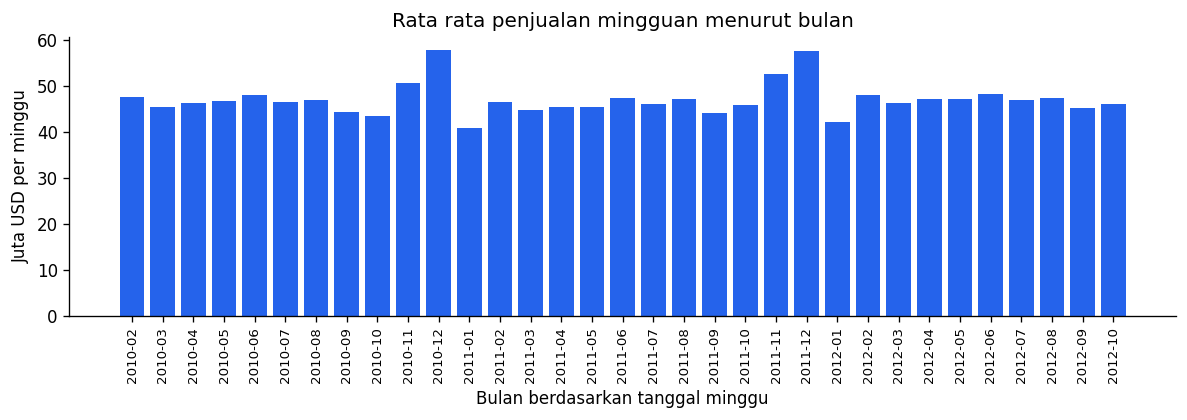

In [5]:
fig, ax = plt.subplots(figsize=(10,3.6))
ax.plot(weekly.Date,weekly.Sales/1e6,color='#2563eb',linewidth=1.5)
h = weekly[weekly.Holiday_Flag.eq(1)]
ax.scatter(h.Date,h.Sales/1e6,color='#dc6b28',label='Minggu berlabel libur',s=24,zorder=3)
ax.set(title='Penjualan mingguan jaringan toko',ylabel='Penjualan (juta USD)',xlabel='Tanggal minggu')
ax.legend(frameon=False);fig.autofmt_xdate();fig.tight_layout()
fig.savefig(ROOT/'outputs/figures/weekly_sales.png');plt.show()
fig, ax = plt.subplots(figsize=(10,3.6))
ax.bar(monthly.Year_Month,monthly.Avg_Weekly_Network/1e6,color='#2563eb')
ax.set(title='Rata rata penjualan mingguan menurut bulan',ylabel='Juta USD per minggu',xlabel='Bulan berdasarkan tanggal minggu')
ax.tick_params(axis='x',rotation=90,labelsize=8);fig.tight_layout()
fig.savefig(ROOT/'outputs/figures/monthly_weekly_average.png');plt.show()
print('Lima minggu tertinggi:')
print(weekly.nlargest(5,'Sales').to_string(index=False))
print('Bulan tertinggi setelah penyesuaian jumlah minggu:')
print(monthly.nlargest(3,'Avg_Weekly_Network').to_string(index=False))

**Hasil pola waktu.** Puncak jaringan tercatat pada 24 Desember 2010, USD 80,93 juta. Desember 2010 tetap tertinggi setelah total bulanan dibagi jumlah minggunya. Label libur saja tidak cukup untuk mengenali semua minggu ramai. Persiapan kapasitas perlu mengikuti kalender dan pola mingguan.

## 6 Membandingkan toko pada minggu yang sama
Total tahunan 2012 akan tampak rendah karena data berhenti pada Oktober. Kita memasangkan minggu ISO yang tersedia pada 2011 dan 2012, membuang minggu 2012 yang belum punya pembanding 2011.

Peringkat kontribusi menjawab siapa yang besar. Pertumbuhan menjawab siapa yang berubah. Toko kecil tidak otomatis bermasalah: luas toko, lokasi, dan target tidak tersedia. Penurunan dipakai sebagai daftar pemeriksaan, bukan vonis kinerja.

Rentang pembanding: 2011-01-07 2011-10-28 vs 2012-01-06 2012-10-26
Minggu sebanding per toko: 43 Perubahan jaringan (%): 2.57
Kontribusi terbesar:
 Store  Total_Sales  Avg_Weekly_Sales  Std_Weekly_Sales    CV_Pct  Share_Pct  Sales_2011  Sales_2012  Matched_Weeks  Change_USD   YoY_Pct
    20 301397792.46      2.107677e+06     275900.562742 13.090269   4.473623 87000419.55 89827709.38             43  2827289.83  3.249743
     4 299543953.38      2.094713e+06     266201.442297 12.708254   4.446107 88214551.63 92771189.24             43  4556637.61  5.165404
    14 288999911.34      2.020978e+06     317569.949476 15.713674   4.289602 84694723.98 77441398.26             43 -7253325.72 -8.564082
    13 286517703.80      2.003620e+06     265506.995776 13.251363   4.252759 82708845.21 86707455.02             43  3998609.81  4.834561
     2 275382440.98      1.925751e+06     237683.694682 12.342388   4.087479 78433649.41 81496695.37             43  3063045.96  3.905270
Perubahan persentase tere

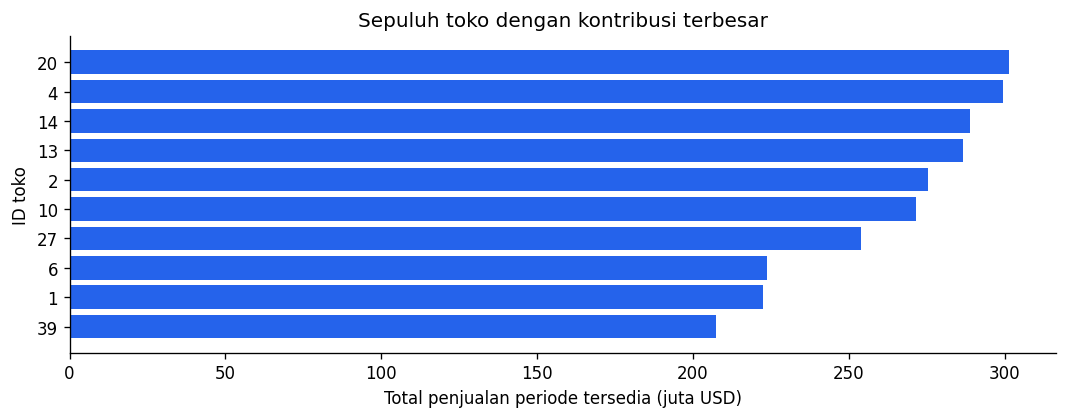

In [6]:
df['ISO_Week'] = df.Date.dt.isocalendar().week.astype(int)
a = df[df.Year.eq(2011)][['Store','ISO_Week','Date','Weekly_Sales']]
b = df[df.Year.eq(2012)][['Store','ISO_Week','Date','Weekly_Sales']]
matched = a.merge(b,on=['Store','ISO_Week'],suffixes=('_2011','_2012'),validate='one_to_one')
assert not matched.empty
comparison = matched.groupby('Store',as_index=False).agg(Sales_2011=('Weekly_Sales_2011','sum'), Sales_2012=('Weekly_Sales_2012','sum'), Matched_Weeks=('ISO_Week','nunique'))
assert comparison.Matched_Weeks.nunique() == 1
comparison['Change_USD'] = comparison.Sales_2012-comparison.Sales_2011
comparison['YoY_Pct'] = (comparison.Sales_2012/comparison.Sales_2011-1)*100
stores = df.groupby('Store',as_index=False).agg(Total_Sales=('Weekly_Sales','sum'),Avg_Weekly_Sales=('Weekly_Sales','mean'),Std_Weekly_Sales=('Weekly_Sales','std'))
stores['CV_Pct'] = stores.Std_Weekly_Sales/stores.Avg_Weekly_Sales*100
stores['Share_Pct'] = stores.Total_Sales / df.Weekly_Sales.sum()*100
stores = stores.merge(comparison,on='Store',validate='one_to_one').sort_values('Total_Sales',ascending=False)
network_yoy = (matched.Weekly_Sales_2012.sum()/matched.Weekly_Sales_2011.sum()-1)*100
stores.to_csv(ROOT/'outputs/reports/store_summary.csv',index=False)
matched.to_csv(ROOT/'outputs/reports/matched_weeks.csv',index=False)
print('Rentang pembanding:',matched.Date_2011.min().date(),matched.Date_2011.max().date(),'vs',matched.Date_2012.min().date(),matched.Date_2012.max().date())
print('Minggu sebanding per toko:',int(comparison.Matched_Weeks.iloc[0]),'Perubahan jaringan (%):',round(network_yoy,2))
print('Kontribusi terbesar:');print(stores.head(5).to_string(index=False))
print('Perubahan persentase terendah:');print(stores.nsmallest(5,'YoY_Pct')[['Store','YoY_Pct','Change_USD','CV_Pct']].to_string(index=False))
print('Penurunan nominal terbesar:');print(stores.nsmallest(5,'Change_USD')[['Store','YoY_Pct','Change_USD']].to_string(index=False))
fig, ax = plt.subplots(figsize=(9,3.6))
top=stores.head(10).sort_values('Total_Sales')
ax.barh(top.Store.astype(str),top.Total_Sales/1e6,color='#2563eb');ax.set(title='Sepuluh toko dengan kontribusi terbesar',xlabel='Total penjualan periode tersedia (juta USD)',ylabel='ID toko');fig.tight_layout()
fig.savefig(ROOT/'outputs/figures/top_stores.png');plt.show()

**Hasil perbandingan toko.** Pada 43 minggu sebanding, penjualan jaringan naik 2,57%, tetapi delapan toko turun. Toko 14 mengalami penurunan nominal terbesar, USD 7,25 juta atau 8,56%. Toko 36 turun 17,50% atau USD 2,82 juta. Mulai pemeriksaan operasional dari kedua toko ini; data belum menjelaskan penyebabnya.

## 7 Memeriksa minggu libur tanpa menyimpulkan sebab
Kita bandingkan rata-rata jaringan per tanggal minggu, bukan total seluruh minggu libur dengan total seluruh minggu biasa. Jumlah minggu kedua kelompok berbeda.

Label Holiday_Flag dipakai sesuai sumber; label ini tidak berarti semua tanggal ramai masuk kelompok libur. Grafik dapat memperlihatkan puncak pada minggu tanpa label libur. Selisih rata-rata adalah hubungan yang terlihat dalam data, bukan kenaikan yang pasti disebabkan hari libur. Kita cek tiap tahun dan mengulang hitungan dengan satu minggu tertinggi dikeluarkan.

In [7]:
holiday = weekly.groupby('Holiday_Flag',as_index=False).agg(Weeks=('Date','size'),Avg_Weekly_Sales=('Sales','mean'),Median_Weekly_Sales=('Sales','median'))
holiday_year = weekly.assign(Year=weekly.Date.dt.year).groupby(['Year','Holiday_Flag'],as_index=False).agg(Weeks=('Date','size'),Avg_Weekly_Sales=('Sales','mean'))
holiday_gap = (holiday.set_index('Holiday_Flag').loc[1,'Avg_Weekly_Sales']/holiday.set_index('Holiday_Flag').loc[0,'Avg_Weekly_Sales']-1)*100
trim=weekly.drop(weekly.Sales.idxmax()).groupby('Holiday_Flag').Sales.mean()
trim_gap=(trim.loc[1]/trim.loc[0]-1)*100
holiday.to_csv(ROOT/'outputs/reports/holiday_summary.csv',index=False)
holiday_year.to_csv(ROOT/'outputs/reports/holiday_by_year.csv',index=False)
print(holiday.to_string(index=False));print(holiday_year.to_string(index=False))
print('Selisih rata-rata libur (%):',round(holiday_gap,2),'Tanpa satu minggu puncak (%):',round(trim_gap,2))

 Holiday_Flag  Weeks  Avg_Weekly_Sales  Median_Weekly_Sales
            0    133      4.685654e+07          46128514.25
            1     10      5.052996e+07          47833126.05
 Year  Holiday_Flag  Weeks  Avg_Weekly_Sales
 2010             0     44      4.746958e+07
 2010             1      4      5.005615e+07
 2011             0     48      4.669718e+07
 2011             1      4      5.168387e+07
 2012             0     41      4.638520e+07
 2012             1      2      4.916973e+07
Selisih rata-rata libur (%): 7.84 Tanpa satu minggu puncak (%): 8.44


**Hasil pemeriksaan libur.** Rata-rata jaringan pada 10 minggu berlabel libur sebesar USD 50,53 juta, dibandingkan USD 46,86 juta pada 133 minggu biasa. Selisihnya 7,84%. Setelah satu minggu puncak dikeluarkan, selisih menjadi 8,44%. Gunakan hasil ini sebagai petunjuk untuk memeriksa kalender, bukan ukuran dampak kausal libur.

## 8 Menguji hubungan faktor ekonomi
Korelasi mengukur apakah dua angka cenderung bergerak bersama, pada rentang -1 sampai 1. Ibarat tinggi badan dan ukuran sepatu: berkaitan tidak berarti salah satunya menyebabkan yang lain.

Korelasi gabungan bisa tercampur oleh perbedaan toko besar dan kecil. Karena itu kita hitung lagi setelah setiap nilai dikurangi rata-rata tokonya. Pemeriksaan kedua mengurangi pengaruh skala tetap toko, tetapi belum mengatasi musim, tren waktu, atau faktor yang tidak tercatat. Kita tidak mengklaim dampak kausal atau memakai hasil ini sebagai aturan mengubah harga.

In [8]:
variables=['Weekly_Sales','Temperature','Fuel_Price','CPI','Unemployment']
pooled=df[variables].corr()['Weekly_Sales'].drop('Weekly_Sales')
within=df[variables]-df.groupby('Store')[variables].transform('mean')
corr=pd.DataFrame({'Pooled_r':pooled,'Within_Store_r':within.corr()['Weekly_Sales'].drop('Weekly_Sales')})
corr.index.name='Variable';corr.to_csv(ROOT/'outputs/reports/correlations.csv')
print(corr.round(4).to_string())

              Pooled_r  Within_Store_r
Variable                              
Temperature    -0.0638         -0.1037
Fuel_Price      0.0095         -0.0420
CPI            -0.0726          0.0188
Unemployment   -0.1062         -0.0501


**Hasil hubungan ekonomi.** Korelasi gabungan dan korelasi setelah pengurangan rata-rata toko sama-sama lemah. Contohnya, CPI berubah dari -0,073 menjadi 0,019. Perbedaan antartoko memengaruhi pembacaan awal. Faktor ekonomi ini belum cukup sebagai dasar keputusan kapasitas tanpa musim, stok, dan konteks toko.

## 9 Menyimpan keluaran yang bisa dipakai ulang
Tabel detail tetap satu baris per toko-minggu. Dashboard menjumlahkan Weekly_Sales dari tabel ini. Jangan mencampurnya dengan tabel ringkasan dalam satu sumber karena total bisa dihitung dua kali. Tidak ada baris Total di tabel detail.

Untuk menjawab “September berapa penjualannya?”, pilih tahun dan bulan. September 2010, 2011, dan 2012 mempunyai nilai berbeda. Contoh di bawah menjadi angka uji dashboard.

In [9]:
detail=df[['Store','Date','Weekly_Sales','Holiday_Flag','Temperature','Fuel_Price','CPI','Unemployment','Year','Month','Year_Month','Holiday_Label','ISO_Week']].copy()
detail.to_csv(ROOT/'data/processed/weekly_sales_clean.csv',index=False,date_format='%Y-%m-%d')
september=monthly[monthly.Year_Month.str.endswith('-09')]
print(september[['Year_Month','Total_Sales','Weeks_Observed','Avg_Weekly_Network']].to_string(index=False))
assert np.isclose(monthly.Total_Sales.sum(),df.Weekly_Sales.sum())
assert np.isclose(stores.Total_Sales.sum(),df.Weekly_Sales.sum())
assert len(detail)==len(df) and not detail.duplicated(['Store','Date']).any()
summary={**kpi,'network_yoy_pct':float(network_yoy),'matched_weeks':int(comparison.Matched_Weeks.iloc[0]),
 'match_start_2011':str(matched.Date_2011.min().date()),'match_end_2011':str(matched.Date_2011.max().date()),
 'match_start_2012':str(matched.Date_2012.min().date()),'match_end_2012':str(matched.Date_2012.max().date()),
 'holiday_gap_pct':float(holiday_gap),'holiday_gap_without_peak_pct':float(trim_gap),
 'top5_share_pct':float(stores.head(5).Share_Pct.sum()),'peak_week':str(weekly.loc[weekly.Sales.idxmax(),'Date'].date()),
 'peak_week_sales':float(weekly.Sales.max()),'best_month_weekly':str(monthly.loc[monthly.Avg_Weekly_Network.idxmax(),'Year_Month']),
 'declining_stores':int(comparison.YoY_Pct.lt(0).sum())}
(ROOT/'outputs/reports/summary.json').write_text(json.dumps(summary,indent=2))
print('Rekonsiliasi total detail, bulanan, dan toko: sesuai')

Year_Month  Total_Sales  Weeks_Observed  Avg_Weekly_Network
   2010-09 177267896.37               4        4.431697e+07
   2011-09 220847738.42               5        4.416955e+07
   2012-09 180645544.47               4        4.516139e+07
Rekonsiliasi total detail, bulanan, dan toko: sesuai


**Jawaban contoh September.** Total September 2012 sebesar USD 180,65 juta, turun 18,20% dari September 2011 yang sebesar USD 220,85 juta. Namun rata-rata mingguan naik 2,25% karena jumlah catatan minggu berubah dari lima menjadi empat. Untuk menilai laju penjualan, baca rata-rata mingguan bersama totalnya.

## 10 Mengirim hasil dari Colab ke Google Sheets
Sel ini **opsional** dan hanya dijalankan di Colab setelah analisis selesai. Login memakai akun Google yang mempunyai akses edit. Isi URL spreadsheet hasil proyek. Tidak perlu menaruh password atau token di notebook.

Kita mengganti isi tab Weekly_Data agar eksekusi berulang tidak menambah duplikat. Tab Dashboard tidak dihapus. Kolom tanggal dikirim sebagai nomor tanggal spreadsheet dan diberi format tanggal. Tanggal yang hanya tampak seperti teks sering membuat filter tanggal dashboard tidak bekerja.

Analogi alurnya: Colab adalah dapur, Sheets meja penyajian, dan dashboard daftar menu yang bisa dipilih. Perubahan resep di Colab baru sampai ke meja setelah sel sinkronisasi dijalankan lagi. Grafik yang interaktif tidak membuat dataset lama berubah menjadi data terkini.

In [10]:
RUN_GOOGLE_SYNC = False  # Ubah menjadi True saat siap login dan memperbarui tab data.
SPREADSHEET_URL = 'https://docs.google.com/spreadsheets/d/1bcIDtRnMCotxuGRRCP31Cyo-Fu1aX4mAwmlVx1b6W2M/edit'
if RUN_GOOGLE_SYNC:
    from google.colab import auth
    import google.auth
    import gspread
    auth.authenticate_user()
    credentials, _ = google.auth.default()
    gc = gspread.authorize(credentials)
    book = gc.open_by_url(SPREADSHEET_URL)
    try:
        ws = book.worksheet('Weekly_Data')
    except gspread.WorksheetNotFound:
        ws = book.add_worksheet(title='Weekly_Data', rows=len(detail)+1, cols=len(detail.columns))
    payload = detail.copy()
    payload['Date'] = (payload['Date']-pd.Timestamp('1899-12-30')).dt.days
    rows = [payload.columns.tolist()] + payload.where(payload.notna(), '').values.tolist()
    ws.resize(rows=len(rows), cols=len(payload.columns))
    ws.clear()
    ws.update(values=rows, range_name='A1', value_input_option='RAW')
    ws.format(f'B2:B{len(rows)}', {'numberFormat': {'type':'DATE','pattern':'yyyy-mm-dd'}})
    ws.freeze(rows=1)
    print('Diperbarui:', book.url, 'Baris:',len(detail))
else:
    print('Sinkronisasi belum dijalankan. Analisis lokal dan ekspor CSV tetap selesai.')

Sinkronisasi belum dijalankan. Analisis lokal dan ekspor CSV tetap selesai.


## 11 Membaca hasil dan menguji pemahaman
Temuan rinci ada pada laporan dan README. Sebelum menetapkan tindakan, periksa tiga hal: penjualan bukan laba, jumlah minggu harus sebanding, dan hubungan libur atau ekonomi belum membuktikan penyebab.

**Latihan:** pilih September 2011 pada dashboard. Cocokkan total dan jumlah minggunya dengan tabel pada bagian 9. Lalu bandingkan dengan September 2012 menggunakan total sekaligus rata-rata mingguan.

**Pertanyaan pemeriksaan:**
1. Kalau bulan A punya lima minggu dan bulan B empat, ukuran mana yang lebih cocok untuk membandingkan laju penjualan?
2. Mengapa total 2012 tidak bisa langsung dibandingkan dengan total 2011?
3. Apakah toko dengan penjualan terkecil pasti paling tidak efisien? Data tambahan apa yang diperlukan?
4. Kalau minggu libur lebih tinggi, apa yang masih diperlukan untuk mengatakan hari libur menyebabkan kenaikan?

**Ringkasan untuk dijelaskan kembali:** kita memeriksa rekap mingguan, membandingkan periode yang setara, lalu memilih waktu dan toko untuk ditindaklanjuti. Dashboard memudahkan pemeriksaan, sedangkan keputusan tetap memerlukan konteks stok, biaya, dan kapasitas.